<font color="#0D9DF0"><h3><b>ANÁLISE DO DESENVOLVIMENTO TURÍSCO BRASILEIRO</b></h3></font>

**Base de dados:** Investing.com (Brent), ANTT/Ministério dos Transportes (rodoviário), ANAC (Anuário 2025)

**Grupo:** Leandro Mendes, Thiago Patente, André e Gabriel Moreira. 

#### Objetivo do trabalho
Investigar se as variações do preço do petróleo (Brent) estão associadas a variações nos setores
de transporte aéreo (voos, tarifa e custos) e rodoviário (passageiros interestaduais).

**Pergunta central:**
Qual é o impacto do preço do petróleo nos setores de transporte aéreo e rodoviário?

A análise é descritiva e exploratória: não identifica causalidade. A unidade de análise é o **ano**
(série temporal), e não a UF; por isso o número de observações é pequeno.

**Etapas do notebook**
1. Coleta e exploração inicial
2. Limpeza e preparação
3. Análise exploratória
4. Funções de visualização
5. Interpretação das análises
6. Síntese e conclusão

#### Importação das bibliotecas

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

INICIO = Path.cwd().resolve()
PROJETO = next(
    (pasta for pasta in [INICIO, *INICIO.parents]
     if (pasta / "util").is_dir() and (pasta / "dados").is_dir()),
    None,
)
if PROJETO is None:
    raise FileNotFoundError("Não encontrei a raiz do projeto.")
if str(PROJETO) not in sys.path:
    sys.path.insert(0, str(PROJETO))

from util import (
    resumo_duplicados, remover_duplicados, resumo_ausentes, salvar_figura,
    achar_aba, achar_coluna, ler_brent, brent_anual, ler_tabela_anual,
    ler_rodoviario, total_oficial_rodoviario, quedas_bruscas, ranking_ufs,
    juntar_series_anuais, variacoes_anuais, tabela_contingencia_sinais,
    teste_robustez_series, grafico_brent_anual, grafico_indices_brent,
    grafico_dispersao_anos, grafico_barras_uf,ler_voos,ler_tarifa,ler_custos
)

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

DADOS = PROJETO / "dados"
ARQ_BRENT = next(DADOS.glob("Dados Históricos - Petróleo Brent Futuros.csv"))
ARQ_ROD = DADOS / "ROD_1_5_4_1_1.xlsx"
ARQ_ANUARIO = next(DADOS.glob("anuario_2025 versão final.xlsx"))

SAIDA = DADOS / "saida" / "pergunta3"
SAIDA.mkdir(parents=True, exist_ok=True)

ANOS_PANDEMIA = [2020, 2021]

---

## 1. Coleta de Dados
**Etapa atual:  COLETA**

Carregamos o histórico diário do Brent, a tabela de passageiros rodoviários interestaduais (> 75 km)
e três abas do Anuário da aviação civil: Fig 2.1 (voos), Fig 6.1 (tarifa média doméstica real)
e Fig 7.8 (custos e despesas de voo por empresa).

In [2]:
print("Brent:", ARQ_BRENT.name)
print("Rodoviário:", ARQ_ROD.name)
print("Anuário:", ARQ_ANUARIO.name)
print("Abas do Anuário:", pd.ExcelFile(ARQ_ANUARIO).sheet_names[:40])

brent = ler_brent(ARQ_BRENT)
brent_ano = brent_anual(brent)

voos_bruto = ler_voos(ARQ_ANUARIO, achar_aba(ARQ_ANUARIO, "Fig 2.1"))
tarifa_bruto = ler_tarifa(ARQ_ANUARIO, achar_aba(ARQ_ANUARIO, "Fig 6.1"))
custos_bruto = ler_custos(ARQ_ANUARIO, achar_aba(ARQ_ANUARIO, "Fig 7.8"))

rodov_bruto = ler_rodoviario(ARQ_ROD)

Brent: Dados Históricos - Petróleo Brent Futuros.csv
Rodoviário: ROD_1_5_4_1_1.xlsx
Anuário: anuario_2025 versão final.xlsx
Abas do Anuário: ['indice', 'Fig 1.1', 'Fig 1.2', 'Fig 1.3', 'Fig 1.4', 'Fig 1.5', 'Fig 1.6', 'Tab 1.1', 'Tab 1.2', 'Tab 1.3', 'Fig 2.1', 'Fig 2.2', 'Fig 2.3', 'Fig 2.4', 'Fig 2.5', 'Fig 2.6', 'Fig 2.7', 'Fig 2.8', 'Fig 2.9', 'Fig 2.10', 'Fig 2.11', 'Fig 2.12', 'Fig 2.13', 'Fig 2.14', 'Fig 2.15', 'Fig 2.16', 'Fig 2.17', 'Fig 2.18', 'Fig 2.19', 'Fig 2.20', 'Fig 2.21', 'Fig 2.22', 'Fig 2.23', 'Fig 2.24', 'Fig 2.25', 'Fig 2.26', 'Fig 2.27', 'Fig 2.28', 'Fig 2.29', 'Fig 2.30']
Aba 'Fig 2.1': anos 2016–2025; colunas: ['voos_dom', 'voos_int']
Aba 'Fig 6.1': anos 2016–2025
Aba 'Fig 7.8': anos 2021–2025; empresas: ['absa', 'azul', 'gol', 'latam', 'sideral']


## 2. Exploração Inicial dos Dados
**Etapa atual:  EXPLORAÇÃO INICIAL**


Verificamos estrutura, tipos, anos disponíveis, **lacunas na série do Brent** e anos parciais.


In [3]:
print("Informações do Brent:")
brent.info()
print("\nResumo anual do Brent (média dos fechamentos):")
print(brent_ano.round(2).to_string(index=False))

anos_brent = sorted(brent_ano["ano"])
faltam = sorted(set(range(min(anos_brent), max(anos_brent) + 1)) - set(anos_brent))
print("\nAnos sem nenhum dado no Brent:", faltam)
print("Anos parciais do Brent:", brent_ano.query("parcial")["ano"].tolist())

print("\nVoos (Fig 2.1):");        print(voos_bruto.head())
print("\nTarifa (Fig 6.1):");      print(tarifa_bruto.head())
print("\nCustos (Fig 7.8):");      print(custos_bruto.head())

print("\nRodoviário — passageiros por ano (soma das UFs):")
print(rodov_bruto.groupby("ano")["passageiros"].sum())
print("Anos — voos:", sorted(voos_bruto["ano"]))
print("Anos — tarifa:", sorted(tarifa_bruto["ano"]))
print("Anos — custos:", sorted(custos_bruto["ano"]))
print("Anos — rodoviário:", sorted(rodov_bruto["ano"].unique()))

Informações do Brent:
<class 'pandas.DataFrame'>
RangeIndex: 4349 entries, 0 to 4348
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   data        4349 non-null   datetime64[us]
 1   fechamento  4349 non-null   float64       
dtypes: datetime64[us](1), float64(1)
memory usage: 68.1 KB

Resumo anual do Brent (média dos fechamentos):
 ano  brent_media  brent_min  brent_max  dias primeira_data ultima_data  parcial
2010        80.34      69.55      94.75   259    2010-01-04  2010-12-31    False
2011       110.91      93.33     126.65   258    2011-01-03  2011-12-30    False
2012       111.68      89.23     126.22   258    2012-01-03  2012-12-31    False
2013       108.70      97.69     118.90   258    2013-01-02  2013-12-31    False
2014        99.49      57.33     115.06   259    2014-01-01  2014-12-31    False
2015        53.60      36.11      67.77   258    2015-01-02  2015-12-31    False
2016        45.1

C:\Users\THIAGO\AppData\Local\Temp\ipykernel_18840\1291157872.py:4: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  print(brent_ano.round(2).to_string(index=False))


## 3. Limpeza de Dados
**Etapa atual:  TRATAMENTO**

Verificamos duplicados, ausentes, a coerência do total rodoviário e quedas bruscas por UF.
Não imputamos valores: médias ou interpolações criariam variações que não existem nos dados.

In [4]:
bases = {
    "Brent": (brent, ["data"]),
    "Voos": (voos_bruto, ["ano"]),
    "Tarifa": (tarifa_bruto, ["ano"]),
    "Custos": (custos_bruto, ["ano"]),
    "Rodoviário": (rodov_bruto, ["uf", "ano"]),
}

print("Diagnóstico de duplicados:")
for nome, (df, chaves) in bases.items():
    dup = resumo_duplicados(df, chaves)
    print(f"\n{nome}: {len(dup)} linhas com chaves repetidas")
    if len(dup):
        print(dup)

print("\nDiagnóstico de ausentes:")
for nome, (df, _) in bases.items():
    print(f"\n{nome}:")
    print(resumo_ausentes(df))


limpas, auditoria = {}, []
for nome, (df, chaves) in bases.items():
    sem_identicos = df.drop_duplicates()
    conflitos = resumo_duplicados(sem_identicos, chaves)
    if len(conflitos):
        print(conflitos)
        raise ValueError(f"{nome}: conferir registros conflitantes.")
    limpa = remover_duplicados(sem_identicos, chaves).dropna(subset=chaves).copy()
    limpas[nome] = limpa
    auditoria.append({"base": nome, "linhas_antes": len(df),
                      "linhas_depois": len(limpa)})

auditoria = pd.DataFrame(auditoria)
auditoria["linhas_removidas"] = auditoria["linhas_antes"] - auditoria["linhas_depois"]
print(auditoria)

brent_limpo = limpas["Brent"]
voos_limpo, tarifa_limpo = limpas["Voos"], limpas["Tarifa"]
custos_limpo, rodov_limpo = limpas["Custos"], limpas["Rodoviário"]


conferencia = pd.DataFrame({
    "soma_ufs": rodov_limpo.groupby("ano")["passageiros"].sum(),
    "total_oficial": total_oficial_rodoviario(ARQ_ROD),
})
conferencia["diferenca"] = conferencia["soma_ufs"] - conferencia["total_oficial"]
print(conferencia)

print("\nQuedas anuais de 60% ou mais por UF (possível quebra de cobertura):")
print(quedas_bruscas(rodov_limpo, limite_pct=-60).to_string(index=False))

print("\nUFs com valor zero em algum ano (serviço inexistente, não ausência):")
print(rodov_limpo.query("passageiros == 0").groupby("uf")["ano"].apply(list))

Diagnóstico de duplicados:

Brent: 0 linhas com chaves repetidas

Voos: 0 linhas com chaves repetidas

Tarifa: 0 linhas com chaves repetidas

Custos: 0 linhas com chaves repetidas

Rodoviário: 0 linhas com chaves repetidas

Diagnóstico de ausentes:

Brent:
Empty DataFrame
Columns: [ausentes, percentual]
Index: []

Voos:
Empty DataFrame
Columns: [ausentes, percentual]
Index: []

Tarifa:
Empty DataFrame
Columns: [ausentes, percentual]
Index: []

Custos:
         ausentes  percentual
sideral         2        40.0

Rodoviário:
Empty DataFrame
Columns: [ausentes, percentual]
Index: []
         base  linhas_antes  linhas_depois  linhas_removidas
0       Brent          4349           4349                 0
1        Voos            10             10                 0
2      Tarifa            10             10                 0
3      Custos             5              5                 0
4  Rodoviário           156            156                 0
        soma_ufs  total_oficial  diferenca
2013

**Decisões de tratamento**

- Registrar o resultado da auditoria. Sem duplicados ou ausentes, nenhum registro é excluído.
- Ausências (por exemplo, Sideral a partir de 2024) não são preenchidas.
- A Média dos fechamentos do ano. O número de dias e a marca de ano parcial acompanham cada ano.
- Os anos sem dados não são estimados nem interpolados. Só entram anos com dados nas duas fontes.
- Zeros (AC e RR) indicam ausência de linhas interestaduais e são mantidos. Não há linha interestaduais ou não foram registradas ou o transporte desses 2 estados são via fluvial
  Quedas bruscas em 2018 (CE, PE, PI, MA) são **sinalizadas**, pois podem indicar mudança de cobertura, não de demanda.
- O total soma só as empresas com dados em todos os anos, para não misturar composições diferentes.

## 4. Transformação e Preparação dos Dados

- Padronizar as colunas do Anuário e selecionar as séries de interesse.
- Integrar por ano com o Brent, mantendo apenas os anos em comum e a marca de ano parcial.
- Calcular as variações anuais (e não os níveis), para evitar correlação espúria por tendência.
- Criar o custo por voo como alternativa que não depende da escala da empresa.

In [5]:
voos = voos_limpo.copy()
voos["voos_total"] = voos["voos_dom"] + voos["voos_int"]

tarifa = tarifa_limpo.copy()

empresas = [c for c in custos_limpo.columns if c != "ano"]
empresas_completas = [c for c in empresas if custos_limpo[c].notna().all()]
print("Empresas nos custos:", empresas)
print("Empresas com dados em todos os anos (entram no total):", empresas_completas)

custos = custos_limpo.copy()
custos["custo_total"] = custos[empresas_completas].sum(axis=1)

aereo = voos.merge(tarifa, on="ano").merge(custos, on="ano")
aereo["custo_por_voo"] = aereo["custo_total"] / aereo["voos_total"]

COLS_AEREO = ["voos_dom", "voos_int", "voos_total",
              "tarifa_real", "custo_total", "custo_por_voo"]
base_aereo = juntar_series_anuais(brent_ano, aereo, COLS_AEREO + empresas)
var_aereo = variacoes_anuais(base_aereo, ["brent_media"] + COLS_AEREO)

voos_tarifa = voos.merge(tarifa, on="ano")
base_voos = juntar_series_anuais(brent_ano, voos_tarifa,
                                 ["voos_dom", "voos_int", "voos_total", "tarifa_real"])
var_voos = variacoes_anuais(base_voos, ["brent_media", "voos_dom", "voos_int",
                                        "voos_total", "tarifa_real"])

# --- Rodoviário
rod_total = (rodov_limpo.groupby("ano")["passageiros"].sum()
             .rename("passageiros").reset_index())
base_rod = juntar_series_anuais(brent_ano, rod_total, ["passageiros"])
var_rod = variacoes_anuais(base_rod, ["brent_media", "passageiros"])


ANOS_PARCIAIS = brent_ano.query("parcial")["ano"].tolist()

print("Anos em comum — aéreo:", base_aereo["ano"].tolist())
print("Anos em comum — rodoviário:", base_rod["ano"].tolist())
if len(base_aereo) < 3 or len(base_rod) < 3:
    print("ATENÇÃO: menos de 3 anos em comum; correlações não são calculáveis.")

print("\nBase aérea:")
print(base_aereo[["ano", "brent_media", "dias", "parcial"] + COLS_AEREO].round(2))
print("\nBase rodoviária:")
print(base_rod.round(2))



Empresas nos custos: ['absa', 'azul', 'gol', 'latam', 'sideral']
Empresas com dados em todos os anos (entram no total): ['absa', 'azul', 'gol', 'latam']
Anos em comum — aéreo: [2021, 2022, 2023, 2024, 2025]
Anos em comum — rodoviário: [2013, 2014, 2015, 2016, 2017, 2018]

Base aérea:
    ano  brent_media  dias  parcial  voos_dom  voos_int  voos_total  tarifa_real   custo_total  custo_por_voo
0  2021        70.95   259    False    545321     47723      593044       597.59  3.574032e+10       60265.88
1  2022        99.04   258    False    730543     94393      824936       727.01  5.387745e+10       65311.07
2  2023        82.17   257    False    789303    122508      911811       698.29  5.854757e+10       64210.20
3  2024        79.86   259    False    784235    142366      926601       670.12  6.670545e+10       71989.40
4  2025        68.03   258    False    796646    162351      958997       647.67  7.136844e+10       74419.88

Base rodoviária:
    ano  brent_media  dias  parcial  


**Atenção às unidades:**  o Brent está em dólar; a tarifa é real, em reais; e os custos podem estar em valores nominais.
O Brent é apenas um *proxy* do custo do combustível de aviação (QAV) e do diesel, que são os canais reais.

## 5. Análise exploratória dos dados
Comparamos **variações anuais**. Com poucos anos, os valores-p são pouco informativos:
o número de observações (n) e o |r| crítico aparecem em todas as tabelas.

### 5.1. Petróleo × transporte aéreo

**Pergunta 1** — Como o preço médio do Brent evoluiu por ano?


In [6]:
print(brent_ano[["ano", "brent_media", "brent_min", "brent_max", "dias", "parcial"]].round(2).to_string(index=False))

 ano  brent_media  brent_min  brent_max  dias  parcial
2010        80.34      69.55      94.75   259    False
2011       110.91      93.33     126.65   258    False
2012       111.68      89.23     126.22   258    False
2013       108.70      97.69     118.90   258    False
2014        99.49      57.33     115.06   259    False
2015        53.60      36.11      67.77   258    False
2016        45.13      27.88      56.82   258    False
2017        54.74      45.05      67.02   258    False
2018        71.69      50.47      86.29   258    False
2019        64.16      54.91      74.57   258    False
2020        43.21      19.33      68.91   259    False
2021        70.95      51.09      86.40   259    False
2022        99.04      76.10     127.98   258    False
2023        82.17      71.84      96.55   257    False
2024        79.86      69.19      91.17   259    False
2025        68.03      58.92      82.03   258    False
2026        90.22      59.96     118.35   217     True


## Analisando o resultado de cima pode-se afirmar que:

O Brent cobre todos os anos de 2010 a 2026, com cerca de 258 dias por ano. Só 2026 é parcial (217 dias), e por isso fica fora das comparações.

- As maiores médias foram as de 2012 (US$ 111,68), 2011 (US$ 110,91) e 2013 (US$ 108,70).
- As quedas de 2014 para 2015 a média caiu cerca de 46% (de US$ 99,49 para US$ 53,60). Em 2020 ficou em US$ 43,21, a menor da série, e o mínimo diário foi de US$ 19,33.
- Atlas a média subiu em 2017–2018 e subiu de novo em 2021 (+64%) e em 2022 (US$ 99,04).
- Depois de 2022, a média caiu em 2023, 2024 e 2025 (US$ 68,03).

O período tem ciclos de queda (2014–2016 e 2020) e de alta (2017–2018 e 2021–2022). Isso permite comparar o transporte em cenários diferentes. Os valores são nominais, em dólares.

**Pergunta 2** — As variações do Brent foram acompanhadas por variações nos voos?



In [7]:
colunas = ["ano", "brent_media_var_pct", "voos_dom_var_pct", "voos_int_var_pct"]
print(var_voos[colunas].round(1).to_string(index=False))
print("\nDomésticos:")
print(tabela_contingencia_sinais(var_voos, "brent_media_var_pct", "voos_dom_var_pct"))
print("\nInternacionais:")
print(tabela_contingencia_sinais(var_voos, "brent_media_var_pct", "voos_int_var_pct"))

 ano  brent_media_var_pct  voos_dom_var_pct  voos_int_var_pct
2016                  NaN               NaN               NaN
2017                 21.3              -2.8              -0.1
2018                 31.0               1.3              12.5
2019                -10.5              -1.7              -3.7
2020                -32.7             -49.3             -60.5
2021                 64.2              34.1             -12.0
2022                 39.6              34.0              97.8
2023                -17.0               8.0              29.8
2024                 -2.8              -0.6              16.2
2025                -14.8               1.6              14.0

Domésticos:
y_mov      caiu  subiu  Total
brent_mov                    
caiu          3      2      5
subiu         1      3      4
Total         4      5      9

Internacionais:
y_mov      caiu  subiu  Total
brent_mov                    
caiu          2      3      5
subiu         2      2      4
Total         4   

**Resultado:** com 9 variações anuais (2017–2025), os voos acompanharam o Brent em parte dos anos, sem padrão claro.

- **Domésticos:** em 6 dos 9 anos o Brent e os voos tiveram o mesmo sentido (3 de queda conjunta e 3 de alta conjunta). Nos outros 3 anos, os sentidos foram opostos.
- **Internacionais:** em 4 dos 9 anos houve o mesmo sentido (2 de queda e 2 de alta). Nos outros 5, foram opostos. Isso é o que se esperaria ao acaso.
- **2020:** o Brent caiu 32,7%, mas os voos caíram ainda mais (−49,3% nos domésticos e −60,5% nos internacionais). A causa foi a pandemia, não o preço do petróleo.
- **2021–2022:** o Brent subiu (+64,2% e +39,6%) e os voos também, por causa da retomada pós-pandemia.
- **2023–2025:** o Brent caiu e os voos internacionais subiram todos os anos (+29,8%, +16,2% e +14,0%).

O resultado mostra associação fraca no sentido das variações. A coincidência nos voos domésticos vem em boa parte de 2020–2022, quando a pandemia afetou os dois. O resultado é descritivo e não indica causalidade.

**Pergunta 3** — As variações do Brent foram acompanhadas por variações na tarifa média real?


In [8]:
print(var_voos[["ano", "brent_media_var_pct", "tarifa_real_var_pct"]].round(1).to_string(index=False))
print(tabela_contingencia_sinais(var_voos, "brent_media_var_pct", "tarifa_real_var_pct"))

 ano  brent_media_var_pct  tarifa_real_var_pct
2016                  NaN                  NaN
2017                 21.3                 -0.6
2018                 31.0                  2.2
2019                -10.5                  7.0
2020                -32.7                -14.5
2021                 64.2                 19.3
2022                 39.6                 21.7
2023                -17.0                 -3.9
2024                 -2.8                 -4.0
2025                -14.8                 -3.3
y_mov      caiu  subiu  Total
brent_mov                    
caiu          4      1      5
subiu         1      3      4
Total         5      4      9


Há 9 variações anuais (2017–2025), a tarifa média real acompanhou o sentido do Brent em 7 dos 9 anos.

- Houve uma queda conjuda de 4 anos , 2020 (Brent −32,7%, tarifa −14,5%) e 2023–2025 (Brent −17,0%, −2,8% e −14,8%; tarifa −3,9%, −4,0% e −3,3%).
- A tarifa variou menos que o Brent na maioria dos anos.

Há associação no sentido das variações, mais clara do que nos voos. Parte dela vem de 2020–2022, quando a pandemia e a retomada afetaram preços e demanda ao mesmo tempo. Com n = 9, o resultado é descritivo e não indica causalidade. O Brent também não é custo direto do combustível, e câmbio e inflação podem influenciar a tarifa.

**Pergunta 4** — Os custos de voo das empresas acompanharam o Brent?


In [9]:
colunas = ["ano", "brent_media_var_pct", "custo_total_var_pct", "custo_por_voo_var_pct"]
print(var_aereo[colunas].round(1).to_string(index=False))
print(tabela_contingencia_sinais(var_aereo, "brent_media_var_pct", "custo_total_var_pct"))

# Custos por empresa em índice (primeiro ano em comum = 100)
ano0 = base_aereo["ano"].min()
indice_empresas = base_aereo.set_index("ano")[empresas].apply(lambda s: s / s.loc[ano0] * 100)
print(f"\nCustos por empresa (índice, {ano0} = 100):")
print(indice_empresas.round(1))

 ano  brent_media_var_pct  custo_total_var_pct  custo_por_voo_var_pct
2021                  NaN                  NaN                    NaN
2022                 39.6                 50.7                    8.4
2023                -17.0                  8.7                   -1.7
2024                 -2.8                 13.9                   12.1
2025                -14.8                  7.0                    3.4
y_mov      subiu  Total
brent_mov              
caiu           3      3
subiu          1      1
Total          4      4

Custos por empresa (índice, 2021 = 100):
       absa   azul    gol  latam  sideral
ano                                      
2021  100.0  100.0  100.0  100.0    100.0
2022  107.5  146.5  132.8  172.7    130.7
2023   68.1  160.0  142.7  192.8    124.4
2024   82.7  150.6  173.2  236.1      NaN
2025   72.7  151.0  184.0  263.2      NaN


Com apenas 4 variações anuais (2022–2025), o custo total das empresas não acompanhou o Brent de forma consistente.

- No ano de 2022, o Brent subiu 39,6% e o custo total subiu 50,7%. O custo por voo subiu 8,4%.
- Nos anos de 2023 a 2025  o Brent caiu (−17,0%, −2,8% e −14,8%), mas o custo total continuou subindo (+8,7%, +13,9% e +7,0%). O custo por voo oscilou (−1,7%, +12,1% e +3,4%).
- No anos de 2021 a 2025,por empresa, o custo subiu 51,0% na Azul, 84,0% na Gol e 163,2% na Latam. A ABSA ficou 27,3% abaixo de 2021. A Sideral só tem dados até 2023 e não entra no total.

A coincidência de sinais ocorreu em 1 dos 4 anos. Parte do aumento do custo total vem do aumento do número de voos, e por isso o custo por voo é a medida mais adequada. Os valores parecem nominais, então a inflação também pesa. Com n = 4, o resultado é descritivo e não indica causalidade. O Brent também não é custo direto do combustível.

### 5.2. Petróleo × transporte rodoviário

**Pergunta 5** — As variações do Brent foram acompanhadas por variações nos passageiros rodoviários?



In [10]:
print(var_rod[["ano", "brent_media", "dias", "parcial", "passageiros",
               "brent_media_var_pct", "passageiros_var_pct"]].round(1).to_string(index=False))
print(tabela_contingencia_sinais(var_rod, "brent_media_var_pct", "passageiros_var_pct"))

 ano  brent_media  dias  parcial  passageiros  brent_media_var_pct  passageiros_var_pct
2013        108.7   258    False   57139194.0                  NaN                  NaN
2014         99.5   259    False   52395169.0                 -8.5                 -8.3
2015         53.6   258    False   48287015.0                -46.1                 -7.8
2016         45.1   258    False   42553456.0                -15.8                -11.9
2017         54.7   258    False   39511267.0                 21.3                 -7.1
2018         71.7   258    False   36973241.0                 31.0                 -6.4
y_mov      caiu  Total
brent_mov             
caiu          3      3
subiu         2      2
Total         5      5


Com 5 variações anuais (2014–2018), os passageiros rodoviários caíram em todos os anos, independentemente do Brent.

-Nos anos de 2014 a 2016 o Brent caiu (−8,5%, −46,1% e −15,8%) e os passageiros também (−8,3%, −7,8% e −11,9%).
- No ano de 2017 a 2018  o Brent subiu (+21,3% e +31,0%), mas os passageiros continuaram caindo (−7,1% e −6,4%).
- Os passageiros passaram de 57,1 milhões em 2013 para 37,0 milhões em 2018 (−35,3%).

A coincidência de sinais ocorreu em 3 dos 5 anos, mas só porque os passageiros caíram sempre. A queda parece seguir uma tendência própria do transporte rodoviário, não o preço do petróleo. Os dados de 2018 podem ter quebra de cobertura em alguns estados. Com n = 5, o resultado é descritivo e não indica causalidade.

**Pergunta 6** — Quais UFs perderam mais passageiros rodoviários entre 2013 e 2018?

In [11]:
rank = ranking_ufs(rodov_limpo, 2013, 2018)
print("Maiores perdas absolutas:")
print(rank.head(5).round(1).to_string(index=False))
print("\nMaiores ganhos ou menores perdas:")
print(rank.tail(5).round(1).to_string(index=False))
print("\nTotal de passageiros 2013 → 2018:")
print(f"{rank['inicio'].sum():,.0f} → {rank['fim'].sum():,.0f} "
      f"({(rank['fim'].sum() / rank['inicio'].sum() - 1) * 100:.1f}%)")

Maiores perdas absolutas:
            uf     inicio       fim    var_abs  var_pct
     SÃO PAULO 12006375.0 7270831.0 -4735544.0    -39.4
  MINAS GERAIS  9232922.0 6935225.0 -2297697.0    -24.9
RIO DE JANEIRO  5050115.0 3013839.0 -2036276.0    -40.3
        PARANÁ  6567229.0 4925317.0 -1641912.0    -25.0
ESPÍRITO SANTO  3173498.0 1743127.0 -1430371.0    -45.1

Maiores ganhos ou menores perdas:
                uf    inicio       fim  var_abs  var_pct
           RORAIMA       0.0    3910.0   3910.0      NaN
              ACRE       0.0    5506.0   5506.0      NaN
          AMAZONAS  124075.0  191648.0  67573.0     54.5
MATO GROSSO DO SUL  620401.0  758033.0 137632.0     22.2
             BAHIA 1722116.0 1881051.0 158935.0      9.2

Total de passageiros 2013 → 2018:
57,139,194 → 36,973,241 (-35.3%)


A queda foi generalizada, mas mais forte nas UFs com maior volume de passageiros. Os dados de 2018 podem ter quebra de cobertura em alguns estados, então o ranking precisa de cautela. O resultado é descritivo e não indica causalidade.

### 5.3. Correlação e robustez

**Pergunta 7** — Há associação entre as variações do Brent e as variações das variáveis do transporte?


In [14]:
CENARIOS = {
    "Todos os anos": {},
    "Sem anos parciais do Brent": {"excluir": ANOS_PARCIAIS},
    "Sem pandemia (2020–2021)": {"excluir": ANOS_PANDEMIA},
    "Brent defasado 1 ano": {"defasagem": 1},
}

ys_voos = ["voos_dom_var_pct", "voos_int_var_pct", "voos_total_var_pct", "tarifa_real_var_pct"]
ys_custos = ["custo_total_var_pct", "custo_por_voo_var_pct"]

robustez_voos = teste_robustez_series(var_voos, "brent_media_var_pct", ys_voos, CENARIOS)
robustez_custos = teste_robustez_series(var_aereo, "brent_media_var_pct", ys_custos, CENARIOS)

print(robustez_voos.to_string(index=False))
print(robustez_custos.to_string(index=False))

           variavel                    cenario                                                 anos  n  pearson  p_pearson  spearman  p_spearman  r_critico_5pct  inclinacao  significativo_5pct
   voos_dom_var_pct              Todos os anos 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025  9    0.767      0.016     0.533       0.139           0.666       0.588                True
   voos_dom_var_pct Sem anos parciais do Brent 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025  9    0.767      0.016     0.533       0.139           0.666       0.588                True
   voos_dom_var_pct   Sem pandemia (2020–2021)             2017, 2018, 2019, 2022, 2023, 2024, 2025  7    0.504      0.249     0.000       1.000           0.754       0.279               False
   voos_dom_var_pct       Brent defasado 1 ano       2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025  8    0.263      0.529     0.119       0.779           0.707       0.209               False
   voos_int_var_pct              To

A associação se concentra em 2020–2022, quando a pandemia e a retomada afetaram Brent, voos e tarifas ao mesmo tempo. Fora desse período, não há evidência consistente. Com poucos anos, vários testes e variáveis de confusão (câmbio, inflação edemanda), o resultado é descritivo e não indica causalidade.

**Pergunta 8** — E no transporte rodoviário?


In [15]:
robustez_rod = teste_robustez_series(var_rod, "brent_media_var_pct",
                                     ["passageiros_var_pct"], CENARIOS)
print(robustez_rod.to_string(index=False))

           variavel                    cenario                         anos  n  pearson  p_pearson  spearman  p_spearman  r_critico_5pct  inclinacao  significativo_5pct
passageiros_var_pct              Todos os anos 2014, 2015, 2016, 2017, 2018  5    0.452      0.445       0.7       0.188           0.878       0.031               False
passageiros_var_pct Sem anos parciais do Brent 2014, 2015, 2016, 2017, 2018  5    0.452      0.445       0.7       0.188           0.878       0.031               False
passageiros_var_pct   Sem pandemia (2020–2021) 2014, 2015, 2016, 2017, 2018  5    0.452      0.445       0.7       0.188           0.878       0.031               False
passageiros_var_pct       Brent defasado 1 ano       2015, 2016, 2017, 2018  4    0.897      0.103       0.8       0.200           0.950       0.079               False



Os passageiros rodoviários caíram em todos os anos, o que indica uma tendência própria, independente do Brent. Com apenas 4 ou 5 observações, o teste tem baixo poder e o resultado é descritivo. Ele não indica causalidade e não permite concluir que o Brent não tem efeito.

**Pergunta 9** — Em níveis (e não em variações), o Brent e as variáveis se movem juntos?


In [17]:
niveis_voos = teste_robustez_series(base_voos, "brent_media",
                                    ["voos_dom", "voos_int", "voos_total", "tarifa_real"],
                                    {"Todos os anos (níveis)": {}})
niveis_custos = teste_robustez_series(base_aereo, "brent_media",
                                      ["custo_total", "custo_por_voo"],
                                      {"Todos os anos (níveis)": {}})
print(niveis_voos.to_string(index=False))
print(niveis_custos.to_string(index=False))

   variavel                cenario                                                       anos  n  pearson  p_pearson  spearman  p_spearman  r_critico_5pct  inclinacao  significativo_5pct
   voos_dom Todos os anos (níveis) 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025 10    0.265      0.460    -0.212       0.556           0.632    2166.423               False
   voos_int Todos os anos (níveis) 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025 10    0.116      0.749     0.042       0.907           0.632     259.058               False
 voos_total Todos os anos (níveis) 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025 10    0.237      0.509    -0.103       0.777           0.632    2425.481               False
tarifa_real Todos os anos (níveis) 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025 10    0.902      0.000     0.903       0.000           0.632       4.044                True
     variavel                cenario                         anos

A correlação da tarifa deve ser lida com cautela. Em níveis, as séries têm tendência e dependência temporal, então o valor-p tende a exagerar a evidência. Em variações anuais, a associação da tarifa desapareceu sem os anos de pandemia. Os custos são nominais e a amostra é pequena. O resultado é descritivo e não indica causalidade.

## 6. Funções de visualização gráfica



Figura salva: C:\Users\THIAGO\Desktop\estudos\POS GRADUAÇÃO\SEMESTRE 1\Python\Aula um\Fundamentos de Python [Aula]\trabalho\dados\saida\pergunta3\brent_anual.png


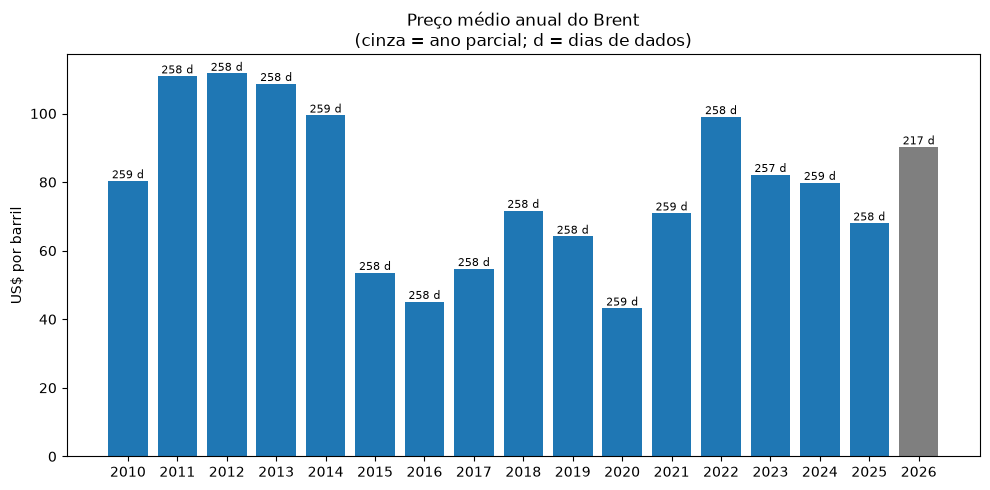

Figura salva: C:\Users\THIAGO\Desktop\estudos\POS GRADUAÇÃO\SEMESTRE 1\Python\Aula um\Fundamentos de Python [Aula]\trabalho\dados\saida\pergunta3\indices_brent_aereo.png


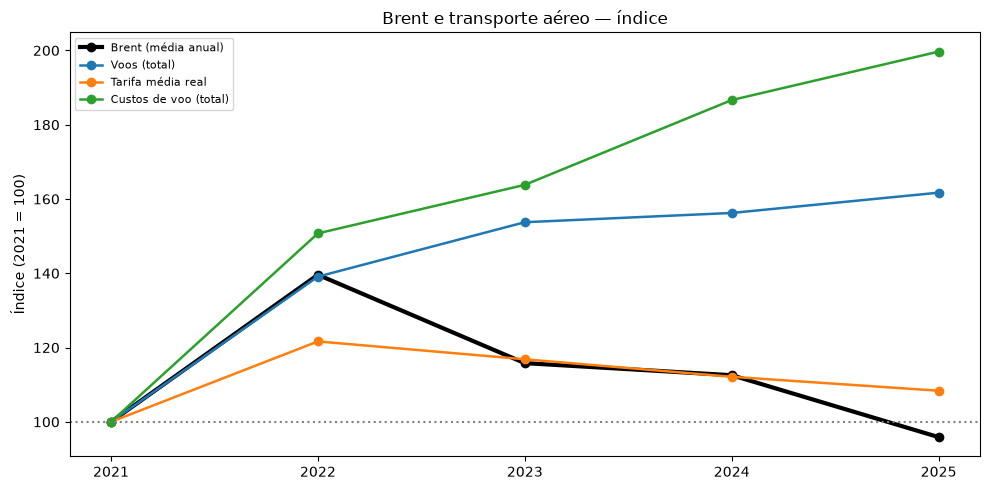

Figura salva: C:\Users\THIAGO\Desktop\estudos\POS GRADUAÇÃO\SEMESTRE 1\Python\Aula um\Fundamentos de Python [Aula]\trabalho\dados\saida\pergunta3\indices_brent_rodoviario.png


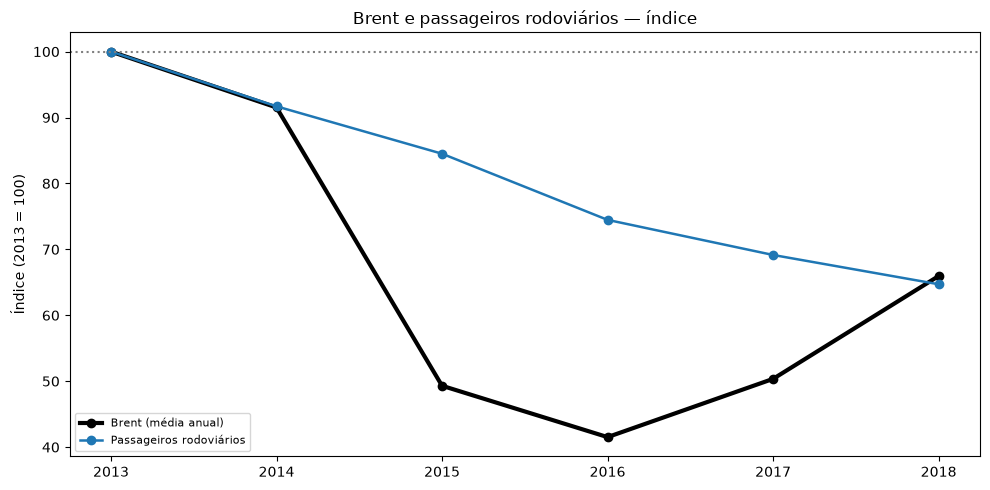

Figura salva: C:\Users\THIAGO\Desktop\estudos\POS GRADUAÇÃO\SEMESTRE 1\Python\Aula um\Fundamentos de Python [Aula]\trabalho\dados\saida\pergunta3\dispersao_tarifa_real_var_pct.png


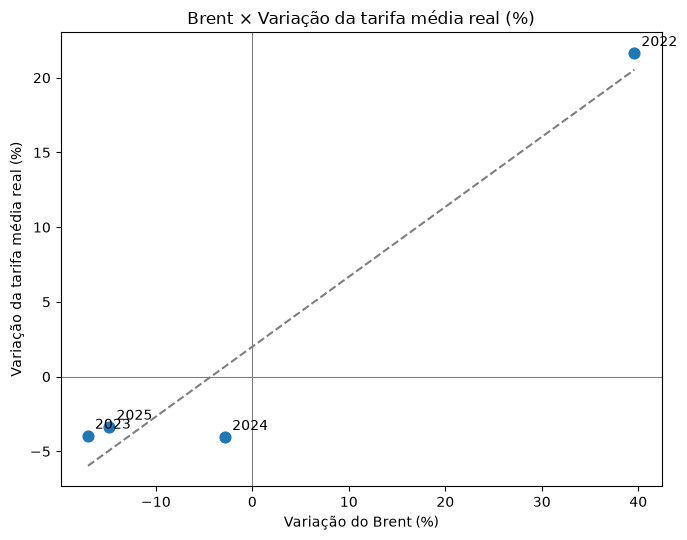

Figura salva: C:\Users\THIAGO\Desktop\estudos\POS GRADUAÇÃO\SEMESTRE 1\Python\Aula um\Fundamentos de Python [Aula]\trabalho\dados\saida\pergunta3\dispersao_custo_total_var_pct.png


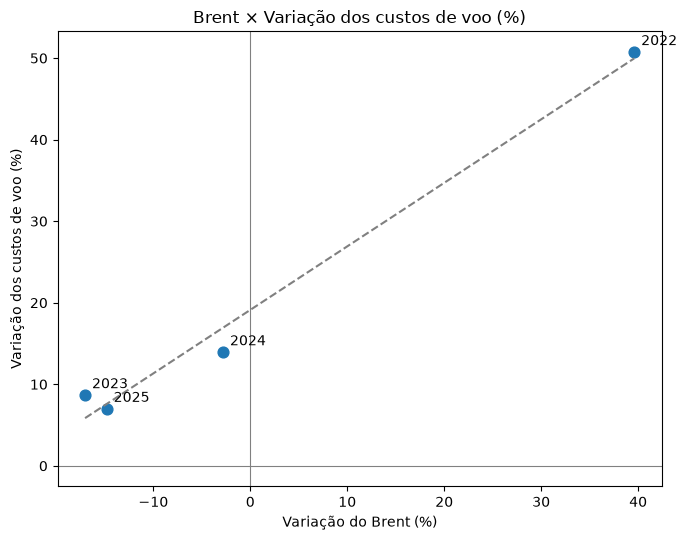

Figura salva: C:\Users\THIAGO\Desktop\estudos\POS GRADUAÇÃO\SEMESTRE 1\Python\Aula um\Fundamentos de Python [Aula]\trabalho\dados\saida\pergunta3\dispersao_voos_total_var_pct.png


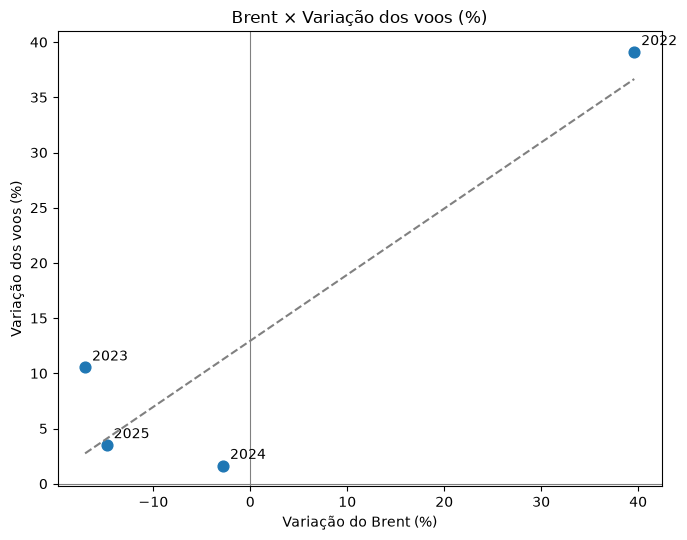

Figura salva: C:\Users\THIAGO\Desktop\estudos\POS GRADUAÇÃO\SEMESTRE 1\Python\Aula um\Fundamentos de Python [Aula]\trabalho\dados\saida\pergunta3\rodoviario_ufs.png


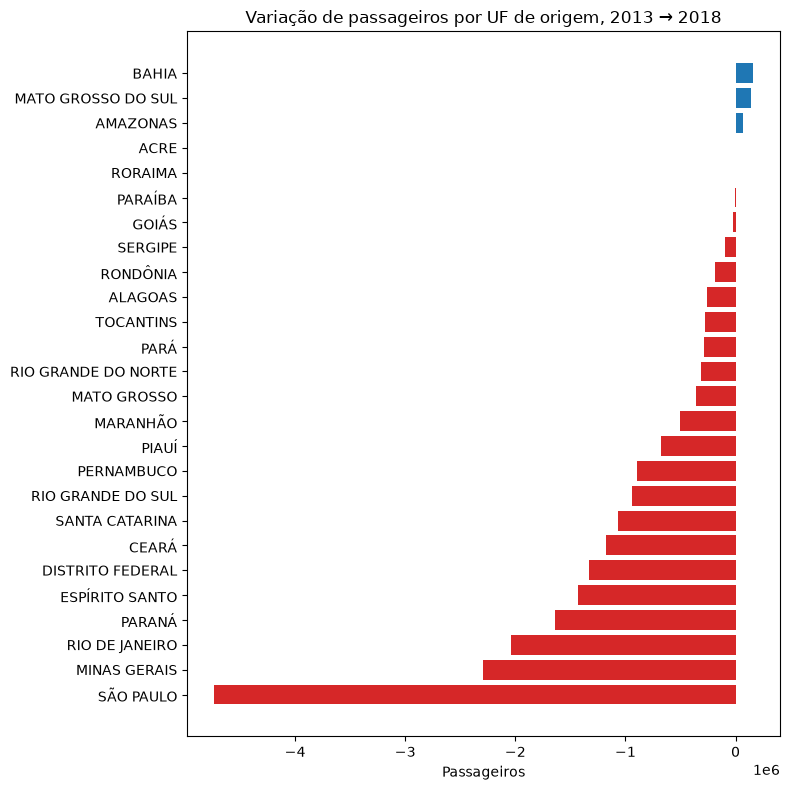

In [18]:
fig = grafico_brent_anual(brent_ano, "Preço médio anual do Brent")
salvar_figura(fig, str(SAIDA / "brent_anual.png"))
plt.show(); plt.close(fig)

fig = grafico_indices_brent(
    base_aereo,
    {"voos_total": "Voos (total)", "tarifa_real": "Tarifa média real",
     "custo_total": "Custos de voo (total)"},
    ano_base=base_aereo["ano"].min(),
    titulo="Brent e transporte aéreo — índice",
)
salvar_figura(fig, str(SAIDA / "indices_brent_aereo.png"))
plt.show(); plt.close(fig)

fig = grafico_indices_brent(
    base_rod, {"passageiros": "Passageiros rodoviários"},
    ano_base=base_rod["ano"].min(), titulo="Brent e passageiros rodoviários — índice",
)
salvar_figura(fig, str(SAIDA / "indices_brent_rodoviario.png"))
plt.show(); plt.close(fig)

for y, rotulo in {"tarifa_real_var_pct": "Variação da tarifa média real (%)",
                  "custo_total_var_pct": "Variação dos custos de voo (%)",
                  "voos_total_var_pct": "Variação dos voos (%)"}.items():
    if y not in var_aereo:
        var_aereo = variacoes_anuais(base_aereo.assign(
            voos_total=base_aereo["voos_dom"] + base_aereo["voos_int"]),
            ["brent_media"] + COLS_AEREO + ["voos_total"])
    fig = grafico_dispersao_anos(var_aereo, "brent_media_var_pct", y,
                                 f"Brent × {rotulo}", "Variação do Brent (%)", rotulo)
    salvar_figura(fig, str(SAIDA / f"dispersao_{y}.png"))
    plt.show(); plt.close(fig)

fig = grafico_barras_uf(rank, "var_abs",
                        "Variação de passageiros por UF de origem, 2013 → 2018",
                        "Passageiros")
salvar_figura(fig, str(SAIDA / "rodoviario_ufs.png"))
plt.show(); plt.close(fig)

## 7. Interpretação das Visualizações

Analisando a variação anual do Brent com a de voos domésticos, voos internacionais e tarifa média real. 2020 é o ponto extremo muito provalmente devido a pandeima. A tarifa varia menos que o Brent.

O custo por empresa em índice em 2025, no caso da Latam está em 263,2, a Gol em 184,0 e a Azul em 151,0. A ABSA está em 72,7, abaixo da base. A Sideral só tem dados até 2023.
A pandemia mostra novamente que houve um aumento no custo de despesas e diminuição da passagens.

Analisando os dados dos número rodoviarios, mostra que o número de passageiros vem caindo todos os anos, de 57,1 milhões (2013) para 37,0 milhões (2018), enquanto o Brent oscila. Os estados mais sofreram foram SP perdeu 4,74 milhões de passageiros (−39,4%), MG 2,30 milhões (−24,9%), RJ 2,04 milhões (−40,3%), PR 1,64 milhão (−25,0%) e ES 1,43 milhão (−45,1%)

Nos dados aéreo, há uma relação razoavel entre o preço do petroleo com a tarifa mas no caso da rodoviaria não pois não tivemos dados de valor das passagens e todo anos está tendo uma queda de viagem.


## 8. Síntese dos Principais Insights

**Brent × aéreo (variações)**
- Os sinais coincidiram em 6 de 9 anos nos voos domésticos, 4 de 9 nos internacionais e 7 de 9 na tarifa real.
- Em 2017 a tarifa ficou praticamente estável (−0,6%). Em 2019 os sentidos foram opostos (Brent −10,5%, tarifa +7,0%).

**Custos das empresas**
- O custo total subiu nos 4 anos (+50,7%, +8,7%, +13,9% e +7,0%), mesmo com o Brent caindo de 2023 a 2025. Os sinais coincidiram em 1 de 4 anos.
- O custo por voo oscilou (+8,4%, −1,7%, +12,1% e +3,4%) e é a medida mais adequada.

**Rodoviário**
- Os passageiros caíram 35,3% de 2013 a 2018.
- Os sinais coincidiram em 3 de 5 anos (2014–2016), só porque os passageiros caíram sempre. Em 2017–2018 o Brent subiu (+21,3% e +31,0%) e os passageiros continuaram caindo (−7,1% e −6,4%).
- SP, MG, RJ, PR e ES somam −12,14 milhões, cerca de 60% da queda nacional (−20,17 milhões). As maiores perdas percentuais foram ES, RJ e SP.
- Só AM (+54,5%), MS (+22,2%) e BA (+9,2%) cresceram, em volumes pequenos. AC e RR aparecem com "ganho" porque não têm registro em 2013.

## 9. Conclusão e Reflexão

### Resposta à pergunta central

**Aéreo.** Há associação no sentido das variações entre o Brent e a tarifa real, e ela é mais clara na tarifa do que nos voos. Essa associação se concentra em 2020–2022 e desaparece sem os anos de pandemia. Há uma relação forte entre tarifas e preço do petrole. O custo total das empresas não acompanhou o Brent. A alta pode se da causa devido o crescimento dos voos e a inflação, pois os valores parecem nominais.

**Rodoviário.** Não há evidência estatística de associação com o Brent. Os passageiros caíram em todos os anos, o que indica uma tendência própria do setor, sem relação visível com o petróleo. A queda foi generalizada e mais forte nas UFs de maior volume.

**Reflexão:** os resultados são descritivos e não indicam causalidade. Muitas correlações altas perderam força quando há o tratamento da pandemia, a tendência e o tamanho da amostra.

## 10. Referências


- INVESTING.COM. *Petróleo Brent Futuros: dados históricos*. Disponível em:https://br.investing.com/commodities/brent-oil-historical-data.

- ANAC. *Anuário do Transporte Aéreo 2025* (Fig 2.1, Fig 6.1 e Fig 7.8). Disponível em: https://www.gov.br/anac/pt-br/assuntos/dados-e-estatisticas/mercado-do-transporte-aereo/panorama-do-mercado/anuario-transporte-aereo.

- [Órgão do arquivo `ROD_1_5_4_1_1.xlsx`]. Disponível em:https://anuariodotransporte.cnt.org.br/2022/Rodoviario/1-5-4-1-/-Linhas-interestaduais-(superiores-a-75-km).